# Traditional Machine Learning

## Data Preprocessing


In [1]:
#Import the google drive

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
#Import the database and view the first 5 rows

import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Life Expectancy Data.csv')


df.head(5)

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [3]:
#Data types for each column

df.dtypes

,0
Country,object
Year,int64
Status,object
Life expectancy,float64
Adult Mortality,float64
infant deaths,int64
Alcohol,float64
percentage expenditure,float64
Hepatitis B,float64
Measles,int64


In [4]:
#Amount of null values in each column

df.isnull().sum()

,0
Country,0
Year,0
Status,0
Life expectancy,10
Adult Mortality,10
infant deaths,0
Alcohol,194
percentage expenditure,0
Hepatitis B,553
Measles,0


In [5]:
#Dropped the null values in life expectancy as this column is the target variable and can cause wrong results

df = df.dropna(subset=['Life expectancy '])

In [6]:
# The Country variable is removed to prevent the model from learning country-specific baseline, meaning the model will focus on relationships between indicators and life expectancy.
# Also it is removed because encoding a 195 different variables will create too much noise.

df = df.drop(columns=['Country'])

In [7]:
# Infant deaths column is removed because it strongly overlaps with under-five deaths column which can introduce multicollinearity and make regression coefficients unstable.

df = df.drop(columns=['infant deaths'])

In [8]:
#Show the first 5 rows

df.head()

,Year,Status,Life expectancy,Adult Mortality,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,2015,Developing,65.0,263.0,0.01,71.279624,65.0,1154,19.1,83,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,2014,Developing,59.9,271.0,0.01,73.523582,62.0,492,18.6,86,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,2013,Developing,59.9,268.0,0.01,73.219243,64.0,430,18.1,89,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,2012,Developing,59.5,272.0,0.01,78.184215,67.0,2787,17.6,93,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,2011,Developing,59.2,275.0,0.01,7.097109,68.0,3013,17.2,97,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [9]:
# Categorise Developed as 1 and Developing as 0

df['Status'] = df['Status'].map({'Developed': 1, 'Developing': 0})

In [10]:
 #Filling the missing values for all the columns
#New name for the db is 'df_imputed'


from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)


In [11]:
#show first 5 rows

df.head()

,Year,Status,Life expectancy,Adult Mortality,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,2015,0,65.0,263.0,0.01,71.279624,65.0,1154,19.1,83,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,2014,0,59.9,271.0,0.01,73.523582,62.0,492,18.6,86,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,2013,0,59.9,268.0,0.01,73.219243,64.0,430,18.1,89,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,2012,0,59.5,272.0,0.01,78.184215,67.0,2787,17.6,93,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,2011,0,59.2,275.0,0.01,7.097109,68.0,3013,17.2,97,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [12]:
#Check if all the null values have been filled or removed

import numpy as np

np.isnan(df_imputed).sum()

,0
Year,0
Status,0
Life expectancy,0
Adult Mortality,0
Alcohol,0
percentage expenditure,0
Hepatitis B,0
Measles,0
BMI,0
under-five deaths,0


In [13]:
# Splitting the data into y (whcih is the result) and x (the variables)
# Data split into train and test. 20% of the data is split for the testing and the rest is for training.
# X is used in the K-Means
# X_train, X_test, y_train and y_test is used for linear regression

from sklearn.model_selection import train_test_split

y = df_imputed['Life expectancy ']
X = df_imputed.drop('Life expectancy ', axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

In [14]:
#Scale the data

from sklearn.preprocessing import StandardScaler
import pandas as pd

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)


X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns
)


X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns
)

## Exploratory Data Analysis

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

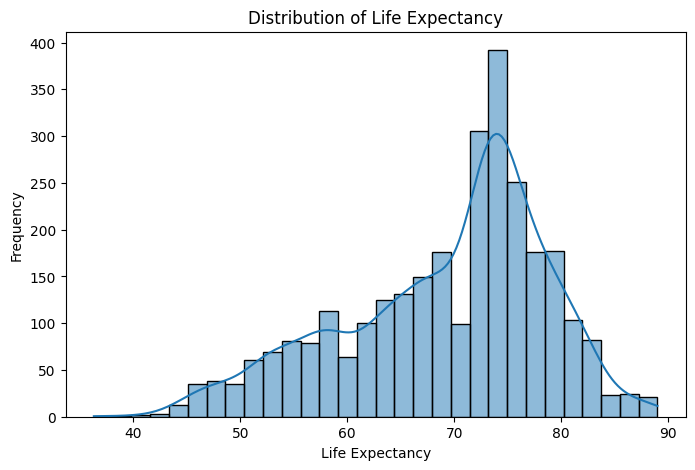

In [16]:
#Graph to show the distribution of the life expectancy

plt.figure(figsize=(8,5))
sns.histplot(df_imputed['Life expectancy '], kde=True)
plt.title("Distribution of Life Expectancy")
plt.xlabel("Life Expectancy")
plt.ylabel("Frequency")
plt.show()

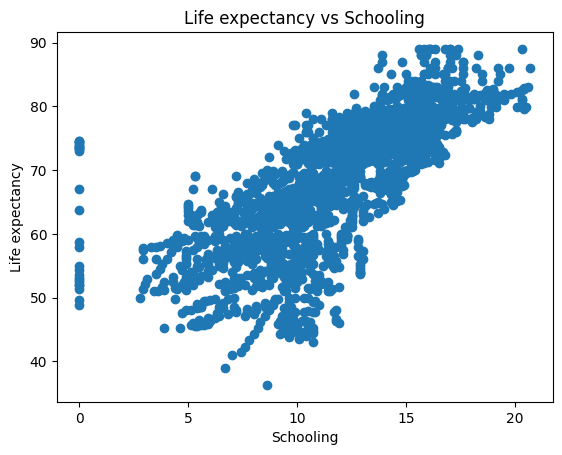

In [17]:
#Life expectancy compared to schooling


plt.scatter(df["Schooling"], df["Life expectancy "])
plt.xlabel("Schooling")
plt.ylabel("Life expectancy")
plt.title("Life expectancy vs Schooling")
plt.show()


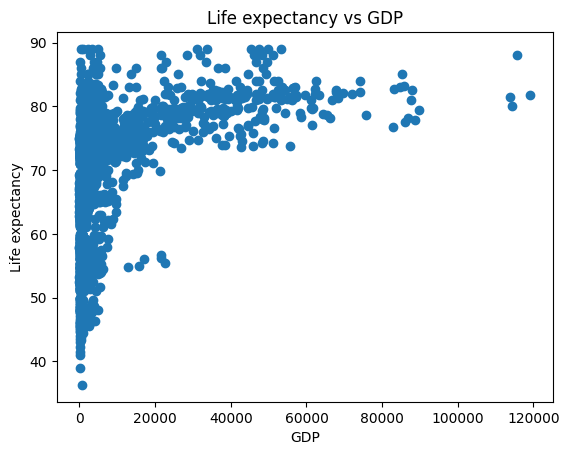

In [18]:
#Life expectancy compared to GDP

plt.scatter(df["GDP"], df["Life expectancy "])
plt.xlabel("GDP")
plt.ylabel("Life expectancy")
plt.title("Life expectancy vs GDP")
plt.show()

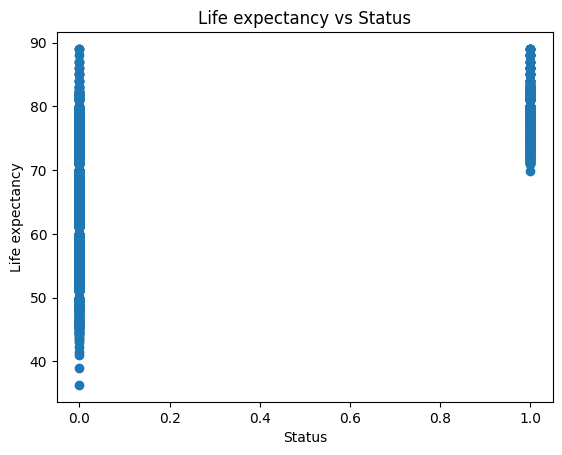

In [19]:
#Life expectancy compared to status

import matplotlib.pyplot as plt

plt.scatter(df["Status"], df["Life expectancy "])
plt.xlabel("Status")
plt.ylabel("Life expectancy")
plt.title("Life expectancy vs Status")
plt.show()

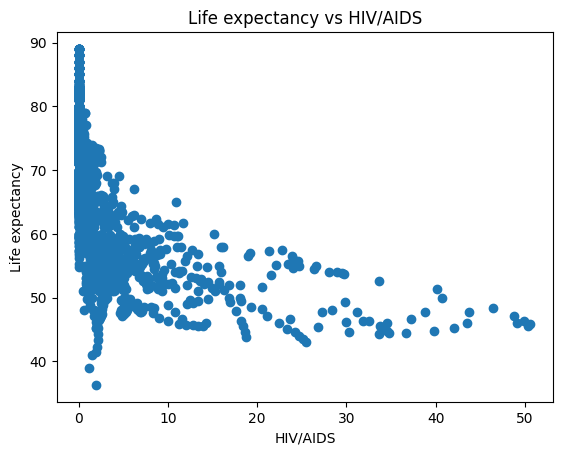

In [20]:
#Life expectancy compared to HIV/AIDS

plt.scatter(df[" HIV/AIDS"], df["Life expectancy "])
plt.xlabel("HIV/AIDS")
plt.ylabel("Life expectancy")
plt.title("Life expectancy vs HIV/AIDS")
plt.show()

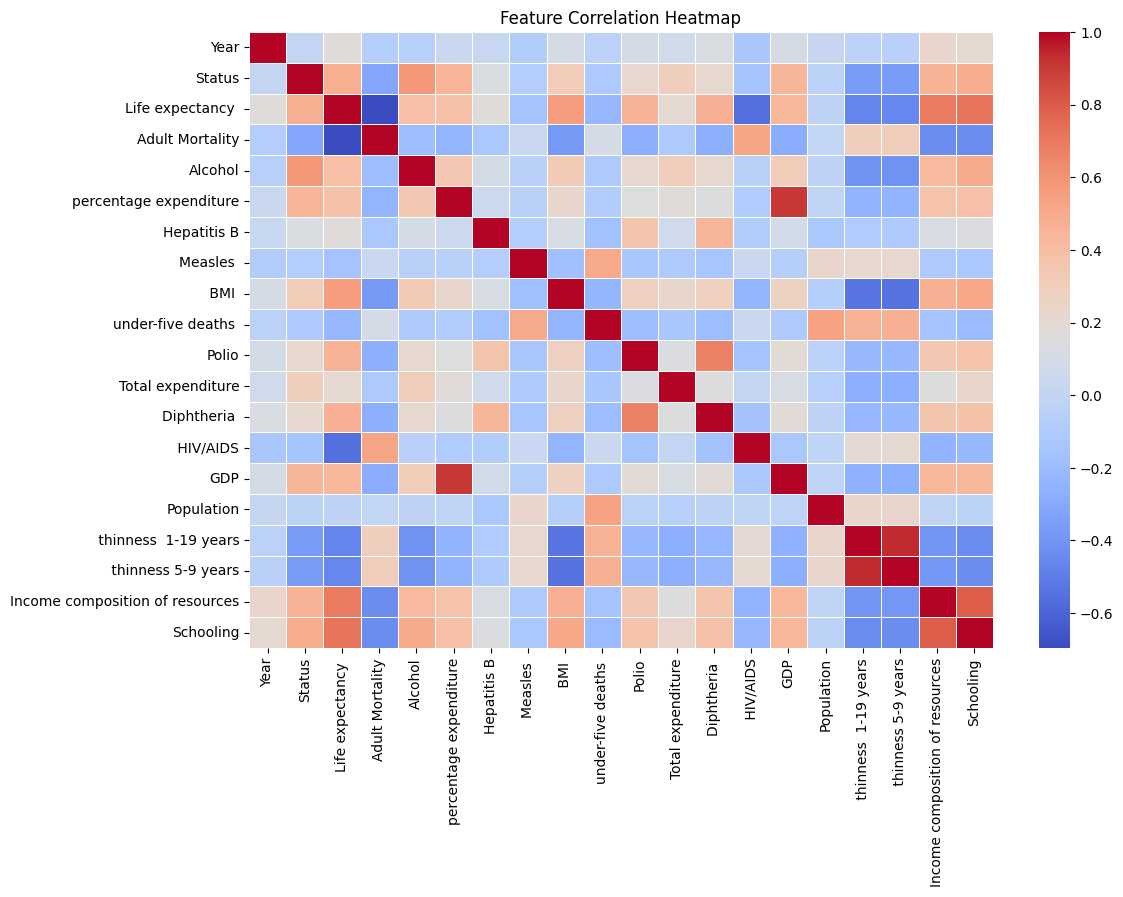

In [21]:
#Correlation Heatmap

plt.figure(figsize=(12,8))
sns.heatmap(df_imputed.corr(), annot=False, cmap='coolwarm', linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

## Linear Regression

In [22]:
from sklearn.linear_model import LinearRegression

In [23]:
#Create the linearRegression model
#Fill it with the training data

model = LinearRegression()
model.fit(X_train_scaled, y_train)

LinearRegression()

In [24]:
#Predicted data based on the test data

y_pred = model.predict(X_test_scaled)

In [25]:
#Check how accurate the model is using r2, mae. rmse

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("R2 =",r2)
print("MAE:", mae)
print("RMSE:", rmse)

R2 = 0.8055869728629047
MAE: 3.0467823839329884
RMSE: 4.149415119367678


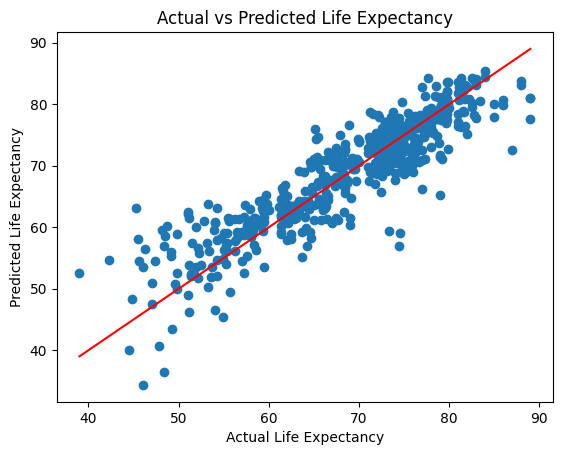

In [26]:
#Actual vs Predicted Life Expectancy

plt.scatter(y_test, y_pred)
plt.xlabel("Actual Life Expectancy")
plt.ylabel("Predicted Life Expectancy")
plt.title("Actual vs Predicted Life Expectancy")
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red')
plt.show()

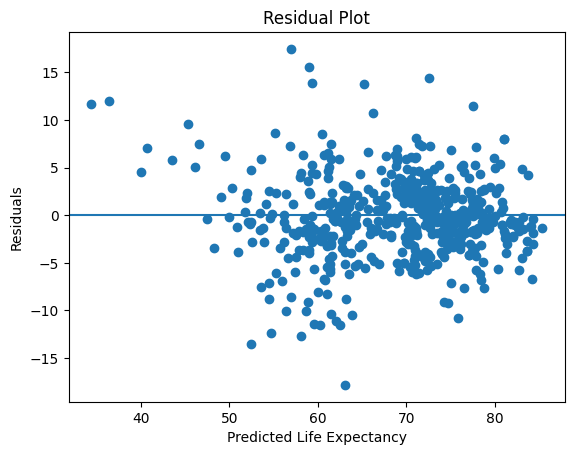

In [27]:
#Scatter diagram of the residuals

residuals = y_test - y_pred

import matplotlib.pyplot as plt

plt.scatter(y_pred, residuals)
plt.xlabel("Predicted Life Expectancy")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.axhline(y=0)
plt.show()

In [28]:
#The coefficient for each column


coefficients = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Coefficient": model.coef_
})

coefficients

,Feature,Coefficient
0,Year,-0.115679
1,Status,0.598178
2,Adult Mortality,-2.440038
3,Alcohol,0.059378
4,percentage expenditure,0.108569
5,Hepatitis B,-0.451969
6,Measles,-0.188959
7,BMI,0.924092
8,under-five deaths,-0.304213
9,Polio,0.803025


## K-Means


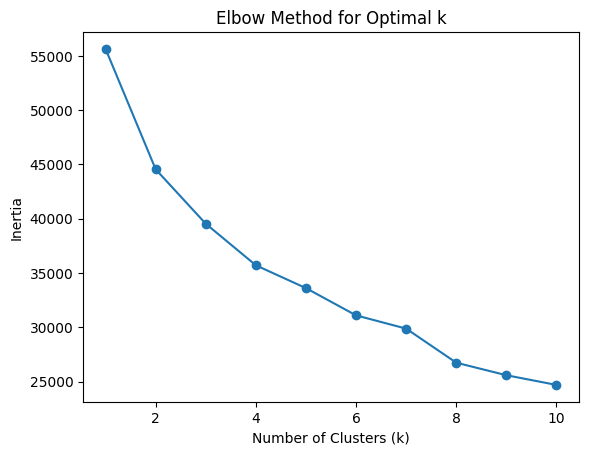

In [29]:
#Elbow method is used to find the k


from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=1)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()

In [30]:
#Running the K-means

kmeans = KMeans(n_clusters=3, random_state=1)
df["Cluster"] = kmeans.fit_predict(X_scaled)

In [31]:
df.groupby("Cluster").mean()

,Year,Status,Life expectancy,Adult Mortality,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
Cluster,,,,,,,,,,,,,,,,,,,,
0,2008.113653,0.005166,72.277048,130.728413,3.996971,331.932628,87.535409,803.070111,44.944955,11.650923,90.375462,5.821961,90.552106,0.317196,5096.855418,9.553400e+06,3.548071,3.579822,0.680605,12.803387
1,2007.470588,0.900178,79.336898,78.631016,9.826903,2902.151557,85.909574,496.766488,52.645811,1.770053,93.759358,7.546165,93.693405,0.100000,23749.727196,7.197417e+06,1.296435,1.266310,0.853963,15.883463
2,2006.694664,0.000000,59.532806,258.176877,2.488107,88.720055,66.522409,5673.830040,20.881054,105.455534,65.583920,5.154316,64.717588,4.576482,1204.679925,1.930736e+07,8.649747,8.713880,0.433143,8.816021


In [32]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, df["Cluster"])
print("Silhouette Score:", score)

Silhouette Score: 0.1801441838117613


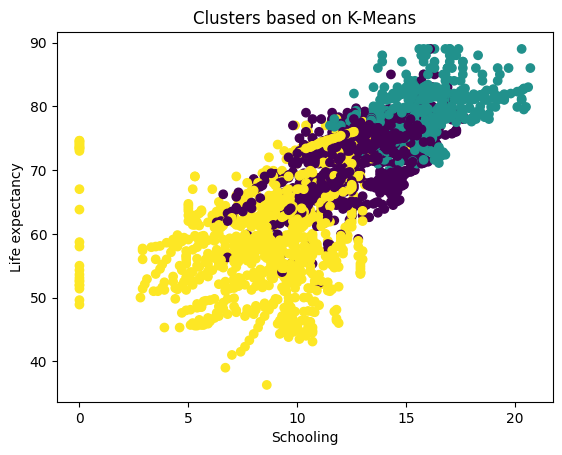

In [33]:
plt.scatter(df["Schooling"], df["Life expectancy "], c=df["Cluster"])
plt.xlabel("Schooling")
plt.ylabel("Life expectancy")
plt.title("Clusters based on K-Means")
plt.show()

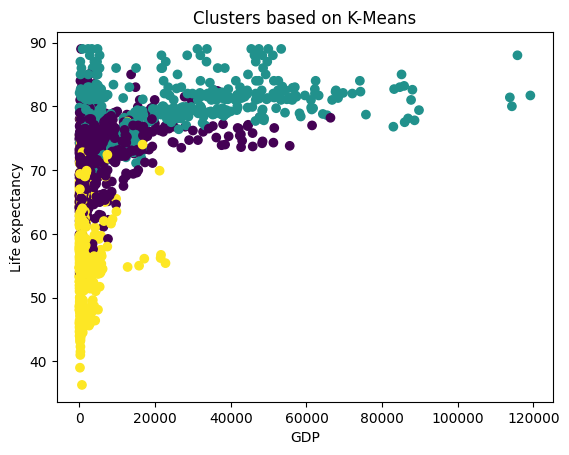

In [34]:
plt.scatter(df["GDP"], df["Life expectancy "], c=df["Cluster"])
plt.xlabel("GDP")
plt.ylabel("Life expectancy")
plt.title("Clusters based on K-Means")
plt.show()

# NLP and Deep Learning

## Data Preprocessing

In [35]:
dfnlp = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/IMDB Dataset.csv')

dfnlp.head(5)

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [36]:
dfnlp.shape


(50000, 2)

In [37]:
dfnlp.isnull().sum()

,0
review,0
sentiment,0


In [38]:
dfnlp["sentiment"].value_counts()

,count
sentiment,
positive,25000
negative,25000


In [39]:
#Convert all to lowercase
dfnlp['review'] = dfnlp['review'].str.lower()
dfnlp['sentiment'] = dfnlp['sentiment'].str.lower()

dfnlp.head(5)

,review,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production. <br /><br />the...,positive
2,i thought this was a wonderful way to spend ti...,positive
3,basically there's a family where a little boy ...,negative
4,"petter mattei's ""love in the time of money"" is...",positive


In [40]:
# Remove HTML tags
dfnlp["review"] = dfnlp["review"].str.replace(r"<.*?>", "",regex=True)

dfnlp.head(5)

,review,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production. the filming tec...,positive
2,i thought this was a wonderful way to spend ti...,positive
3,basically there's a family where a little boy ...,negative
4,"petter mattei's ""love in the time of money"" is...",positive


In [41]:
# Keep only letters and spaces
dfnlp["review"] = dfnlp["review"].str.replace(r"[^a-zA-Z\s]", "", regex=True)

dfnlp.head(5)

,review,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production the filming tech...,positive
2,i thought this was a wonderful way to spend ti...,positive
3,basically theres a family where a little boy j...,negative
4,petter matteis love in the time of money is a ...,positive


In [42]:
dfnlp["review"].iloc[0]

'one of the other reviewers has mentioned that after watching just  oz episode youll be hooked they are right as this is exactly what happened with methe first thing that struck me about oz was its brutality and unflinching scenes of violence which set in right from the word go trust me this is not a show for the faint hearted or timid this show pulls no punches with regards to drugs sex or violence its is hardcore in the classic use of the wordit is called oz as that is the nickname given to the oswald maximum security state penitentary it focuses mainly on emerald city an experimental section of the prison where all the cells have glass fronts and face inwards so privacy is not high on the agenda em city is home to manyaryans muslims gangstas latinos christians italians irish and moreso scuffles death stares dodgy dealings and shady agreements are never far awayi would say the main appeal of the show is due to the fact that it goes where other shows wouldnt dare forget pretty picture

In [43]:
dfnlp["sentiment"] = dfnlp["sentiment"].map({
    "positive": 1,
    "negative": 0
})

In [44]:
dfnlp.head(5)

,review,sentiment
0,one of the other reviewers has mentioned that ...,1
1,a wonderful little production the filming tech...,1
2,i thought this was a wonderful way to spend ti...,1
3,basically theres a family where a little boy j...,0
4,petter matteis love in the time of money is a ...,1


In [45]:
from tensorflow.keras.preprocessing.text import Tokenizer

# Keep only the most common 10,000 words
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")

# Learn the word index from the review text
tokenizer.fit_on_texts(dfnlp["review"])

# Convert each review into a sequence of integers
sequences = tokenizer.texts_to_sequences(dfnlp["review"])

# View one tokenised review
print(sequences[0])

[28, 5, 2, 78, 1914, 43, 1051, 12, 101, 145, 40, 3269, 391, 457, 26, 3115, 34, 23, 206, 14, 11, 7, 590, 47, 580, 15, 7420, 88, 146, 12, 3190, 69, 42, 3269, 13, 29, 5436, 3, 1, 132, 5, 581, 61, 284, 8, 206, 36, 2, 658, 138, 1709, 69, 11, 7, 21, 4, 118, 16, 2, 8026, 5628, 39, 1, 11, 118, 2456, 55, 5839, 15, 5542, 6, 1445, 381, 39, 581, 29, 7, 3350, 8, 2, 351, 340, 5, 2, 1, 7, 461, 3269, 14, 12, 7, 2, 1, 345, 6, 2, 1, 6688, 2514, 1048, 1, 9, 2580, 1352, 20, 1, 530, 33, 4624, 2473, 5, 2, 1186, 113, 31, 2, 6897, 25, 2915, 1, 3, 405, 1, 38, 1, 7, 21, 318, 20, 2, 4960, 3633, 530, 7, 342, 6, 1, 8151, 1, 1, 5052, 7612, 2411, 3, 1, 1, 328, 8932, 7206, 1, 3, 8401, 1, 23, 109, 226, 1, 57, 125, 2, 269, 1275, 5, 2, 118, 7, 660, 6, 2, 187, 12, 9, 262, 113, 78, 256, 545, 2938, 814, 179, 1248, 4243, 16, 2452, 1085, 814, 1390, 814, 1, 147, 964, 182, 2, 88, 391, 10, 120, 203, 3190, 69, 14, 38, 1553, 9, 13, 2170, 10, 394, 125, 10, 13, 1528, 16, 9, 18, 14, 10, 278, 50, 10, 1442, 4, 1226, 16, 3269, 3, 183, 

In [46]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Set a fixed sequence length
max_length = 200

# Pad shorter reviews with zeros and truncate longer reviews
padded_sequences = pad_sequences(
    sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

# Check shape of padded data
print(padded_sequences.shape)

# View one padded review
print(padded_sequences[0])

(50000, 200)
[  28    5    2   78 1914   43 1051   12  101  145   40 3269  391  457
   26 3115   34   23  206   14   11    7  590   47  580   15 7420   88
  146   12 3190   69   42 3269   13   29 5436    3    1  132    5  581
   61  284    8  206   36    2  658  138 1709   69   11    7   21    4
  118   16    2 8026 5628   39    1   11  118 2456   55 5839   15 5542
    6 1445  381   39  581   29    7 3350    8    2  351  340    5    2
    1    7  461 3269   14   12    7    2    1  345    6    2    1 6688
 2514 1048    1    9 2580 1352   20    1  530   33 4624 2473    5    2
 1186  113   31    2 6897   25 2915    1    3  405    1   38    1    7
   21  318   20    2 4960 3633  530    7  342    6    1 8151    1    1
 5052 7612 2411    3    1    1  328 8932 7206    1    3 8401    1   23
  109  226    1   57  125    2  269 1275    5    2  118    7  660    6
    2  187   12    9  262  113   78  256  545 2938  814  179 1248 4243
   16 2452 1085  814 1390  814    1  147  964  182    2   88  39

In [47]:
from sklearn.model_selection import train_test_split

# Input features = padded reviews
nX = padded_sequences

# Target labels = sentiment
ny = dfnlp["sentiment"]

# Split into training and testing sets
nX_train, nX_test, ny_train, ny_test = train_test_split(
    nX, ny, test_size=0.3, random_state=1
)

# Check shapes
print("nX_train shape:", nX_train.shape)
print("nX_test shape:", nX_test.shape)
print("ny_train shape:", ny_train.shape)
print("ny_test shape:", ny_test.shape)

nX_train shape: (35000, 200)
nX_test shape: (15000, 200)
ny_train shape: (35000,)
ny_test shape: (15000,)


In [48]:
# Number of samples to use for validation
validation_size = 5000

# First 5000 → validation set
nX_val = nX_train[:validation_size]
ny_val = ny_train[:validation_size]

# Remaining → actual training set
nX_train_partial = nX_train[validation_size:]
ny_train_partial = ny_train[validation_size:]

# Check shapes
print("Training set:", nX_train_partial.shape)
print("Validation set:", nX_val.shape)
print("Test set:", nX_test.shape)

Training set: (30000, 200)
Validation set: (5000, 200)
Test set: (15000, 200)


## LSTM

In [49]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dropout, Dense

# Set main hyperparameters
vocab_size = 10000
embedding_dim = 128
max_length = 200
lstm_units = 64

# Build the LSTM model
lstm_model = Sequential([
    # Converts word indices into dense word vectors
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),

    # Reads the review sequence and learns context
    LSTM(lstm_units),

    # Helps reduce overfitting
    Dropout(0.5),

    # Final output layer for binary classification
    Dense(1, activation="sigmoid")
])

# Compile the model
lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Show model structure
lstm_model.build(input_shape=(None, max_length))
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329,473 (5.07 MB)

 Trainable params: 1,329,473 (5.07 MB)

 Non-trainable params: 0 (0.00 B)

In [58]:
from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss does not improve
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

In [59]:
history_lstm = lstm_model.fit(
    nX_train_partial,
    ny_train_partial,
    epochs=10,
    batch_size=64,
    validation_data=(nX_val, ny_val),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.5555 - loss: 0.6862 - val_accuracy: 0.5582 - val_loss: 0.6822
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.6692 - loss: 0.6078 - val_accuracy: 0.7714 - val_loss: 0.5159
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.7828 - loss: 0.4915 - val_accuracy: 0.5060 - val_loss: 0.6938
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.5590 - loss: 0.6812 - val_accuracy: 0.6748 - val_loss: 0.6224
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.8252 - loss: 0.4200 - val_accuracy: 0.8494 - val_loss: 0.3708
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9007 - loss: 0.2780 - val_accuracy: 0.8584 - val_loss: 0.3525
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9284 - loss: 0.2161 - val_accuracy: 0.8572 - val_loss: 0.3932
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9485 - loss: 0.1705 - val_accu

In [60]:
# Evaluate model on test data
test_loss, test_accuracy = lstm_model.evaluate(nX_test, ny_test, verbose=1)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8603 - loss: 0.3452
Test Loss: 0.3452366292476654
Test Accuracy: 0.8602666854858398


In [61]:
import numpy as np

# Predict probabilities
y_pred_prob = lstm_model.predict(nX_test)

# Convert probabilities → 0 or 1
y_pred = (y_pred_prob > 0.5).astype(int)

469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


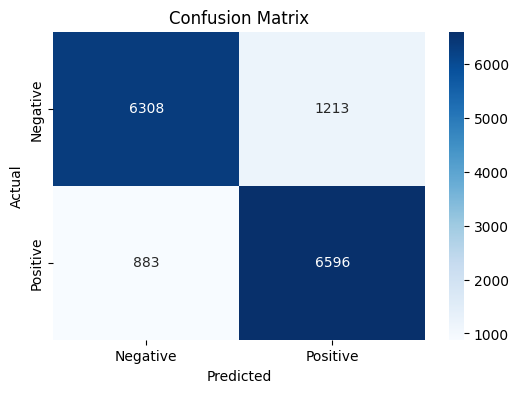

In [62]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(ny_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [63]:
from sklearn.metrics import classification_report

print(classification_report(ny_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.84      0.86      7521
           1       0.84      0.88      0.86      7479

    accuracy                           0.86     15000
   macro avg       0.86      0.86      0.86     15000
weighted avg       0.86      0.86      0.86     15000



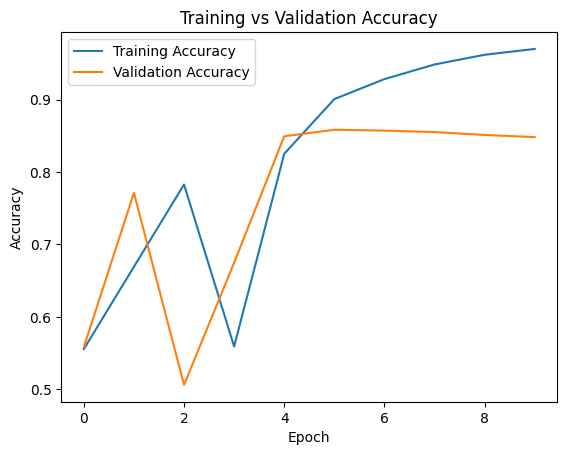

In [64]:
# Accuracy graph
plt.plot(history_lstm.history['accuracy'], label='Training Accuracy')
plt.plot(history_lstm.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.show()


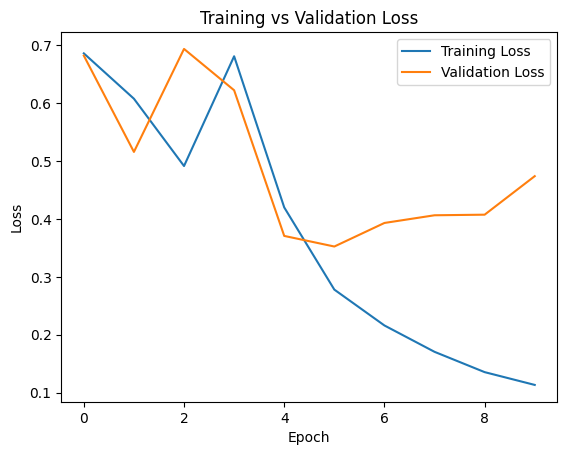

In [65]:
# Loss graph
plt.plot(history_lstm.history['loss'], label='Training Loss')
plt.plot(history_lstm.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()